In [1]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

In [2]:
####################################################
# INPUTS
####################################################
pm10 = ctrl.Antecedent(np.arange(0, 151, 1), "pm10")
pm25 = ctrl.Antecedent(np.arange(0, 101, 1), "pm25")
wind = ctrl.Antecedent(np.arange(0, 41, 1), "wind")

####################################################
# OUTPUT
####################################################
risk = ctrl.Consequent(np.arange(0, 10.1, 0.1), "environmental_risk")

####################################################
# PM10
####################################################
pm10["good"] = fuzz.zmf(pm10.universe, 18, 25)
pm10["fair"] = fuzz.pimf(pm10.universe, 19, 21, 33, 38)
pm10["moderate"] = fuzz.pimf(pm10.universe, 31, 36, 45, 55)
pm10["poor"] = fuzz.pimf(pm10.universe, 46, 51, 90, 110)
pm10["very_poor"] = fuzz.smf(pm10.universe, 91, 101)

####################################################
# PM25
####################################################
pm25["good"] = fuzz.zmf(pm25.universe, 9, 12)
pm25["fair"] = fuzz.pimf(pm25.universe, 9, 11, 18, 22)
pm25["moderate"] = fuzz.pimf(pm25.universe, 18, 21, 24, 28)
pm25["poor"] = fuzz.pimf(pm25.universe, 23, 26, 45, 55)
pm25["very_poor"] = fuzz.smf(pm25.universe, 46, 55)

####################################################
# WIND
####################################################
wind["low"] = fuzz.trapmf(wind.universe, [0, 0, 6, 12])
wind["medium"] = fuzz.trimf(wind.universe, [8, 18, 28])
wind["high"] = fuzz.trapmf(wind.universe, [22, 30, 40, 40])

####################################################
# OUTPUT
####################################################
risk["low"] = fuzz.trapmf(risk.universe, [0, 0, 2.5, 4])
risk["medium"] = fuzz.trimf(risk.universe, [3, 5, 7])
risk["high"] = fuzz.trapmf(risk.universe, [6, 8, 10, 10])

####################################################
# RULES
####################################################
rules = [
    ctrl.Rule(pm10["good"] & pm25["good"], risk["low"]),
    ctrl.Rule(pm10["good"] & pm25["fair"] & ~wind["high"], risk["low"]),
    ctrl.Rule(pm10["good"] & pm25["moderate"] & ~wind["high"], risk["medium"]),
    ctrl.Rule(pm10["good"] & pm25["poor"] & ~wind["high"], risk["high"]),
    ctrl.Rule(pm10["good"] & pm25["very_poor"], risk["high"]),
    ctrl.Rule(pm10["fair"] & pm25["good"] & ~wind["high"], risk["low"]),
    ctrl.Rule(pm10["fair"] & pm25["fair"] & ~wind["high"], risk["low"]),
    ctrl.Rule(pm10["fair"] & pm25["moderate"] & ~wind["high"], risk["medium"]),
    ctrl.Rule(pm10["fair"] & pm25["poor"] & ~wind["high"], risk["high"]),
    ctrl.Rule(pm10["fair"] & pm25["very_poor"], risk["high"]),
    ctrl.Rule(pm10["moderate"] & pm25["good"] & ~wind["high"], risk["medium"]),
    ctrl.Rule(pm10["moderate"] & pm25["fair"] & ~wind["high"], risk["medium"]),
    ctrl.Rule(pm10["moderate"] & pm25["moderate"] & ~wind["high"], risk["medium"]),
    ctrl.Rule(pm10["moderate"] & pm25["poor"] & ~wind["high"], risk["high"]),
    ctrl.Rule(pm10["moderate"] & pm25["very_poor"], risk["high"]),
    ctrl.Rule(pm10["good"] & pm25["fair"] & wind["high"], risk["low"]),
    ctrl.Rule(pm10["good"] & pm25["moderate"] & wind["high"], risk["low"]),
    ctrl.Rule(pm10["good"] & pm25["poor"] & wind["high"], risk["medium"]),
    ctrl.Rule(pm10["fair"] & pm25["good"] & wind["high"], risk["low"]),
    ctrl.Rule(pm10["fair"] & pm25["fair"] & wind["high"], risk["low"]),
    ctrl.Rule(pm10["fair"] & pm25["moderate"] & wind["high"], risk["low"]),
    ctrl.Rule(pm10["fair"] & pm25["poor"] & wind["high"], risk["medium"]),
    ctrl.Rule(pm10["moderate"] & pm25["good"] & wind["high"], risk["low"]),
    ctrl.Rule(pm10["moderate"] & pm25["fair"] & wind["high"], risk["low"]),
    ctrl.Rule(pm10["moderate"] & pm25["moderate"] & wind["high"], risk["low"]),
    ctrl.Rule(pm10["moderate"] & pm25["poor"] & wind["high"], risk["medium"]),
    ctrl.Rule(pm10["poor"] & ~wind["high"], risk["high"]),
    ctrl.Rule(pm10["very_poor"], risk["high"]),
    ctrl.Rule(pm25["very_poor"], risk["high"])
]

####################################################
# CONTROL SYSTEM
####################################################
fis = ctrl.ControlSystem(rules)
simulation = ctrl.ControlSystemSimulation(fis)

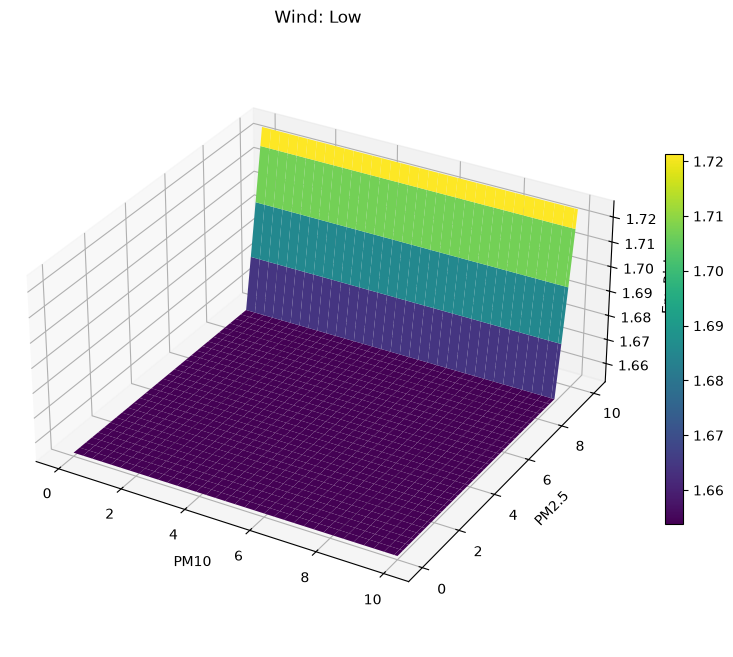

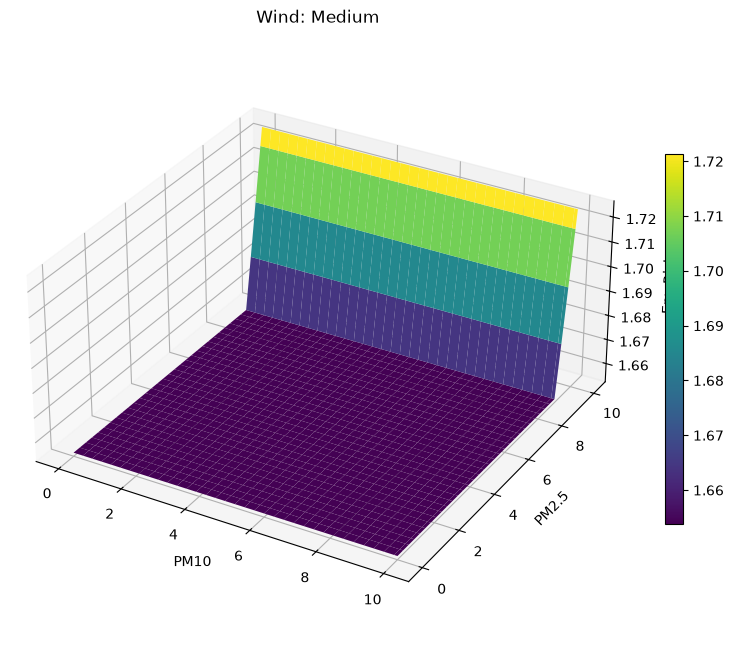

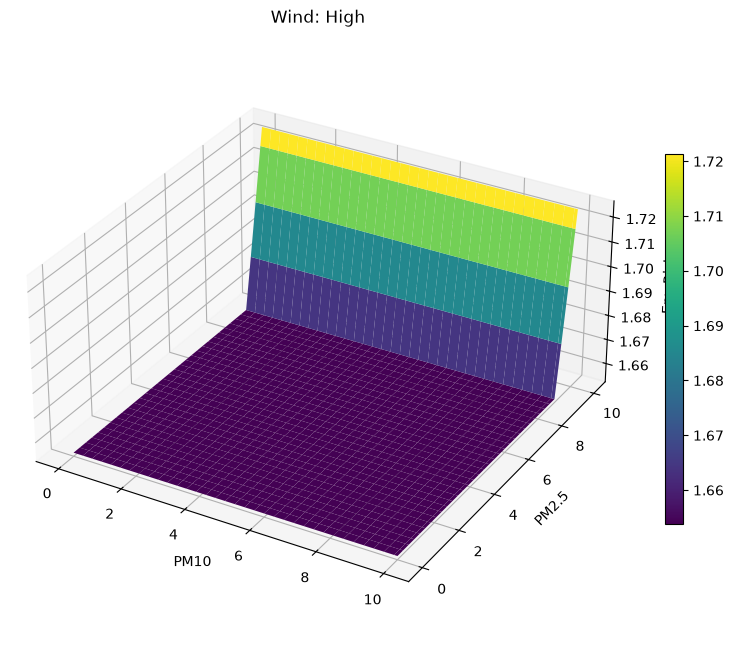

In [3]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_surface(wind_inp, title):

    pm10_range = np.linspace(0, 10, 101)
    pm25_range = np.linspace(0, 10, 101)

    PM10, PM25 = np.meshgrid(pm10_range, pm25_range)

    OUTPUT = np.zeros_like(PM10)

    for i in range(PM10.shape[0]):
        for j in range(PM10.shape[1]):

            sim = ctrl.ControlSystemSimulation(fis)

            sim.input["pm10"] = PM10[i, j]
            sim.input["pm25"] = PM25[i, j]
            sim.input["wind"] = wind_inp

            sim.compute()

            OUTPUT[i, j] = sim.output["environmental_risk"]

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    surface = ax.plot_surface(
        PM10,
        PM25,
        OUTPUT,
        cmap="viridis",
        edgecolor="none",
        antialiased=True
    )

    ax.set_xlabel("PM10")
    ax.set_ylabel("PM2.5")
    ax.set_zlabel("Env Risk")
    ax.set_title(title)
    ax.set_box_aspect((1,1,0.5))

    fig.colorbar(surface, shrink=0.6)

    plt.show()

plot_surface(0, "Wind: Low")
plot_surface(5, "Wind: Medium")
plot_surface(10, "Wind: High")